[Sommaire](00_sommaire.ipynb) · ⬅ [Thème 1 — Listes, sets, dicts](theme1_listes_sets_dicts.ipynb) · [Thème 3 — Fenêtre glissante](theme3_fenetre_deux_pointeurs.ipynb) ➡

# Thème 2 — Matrices (grilles) et simulation

**Dans ce notebook, tu vas apprendre :**
- représenter une grille en Python et désigner une case avec `m[i][j]` ;
- trouver les voisins d'une case sans sortir de la grille ;
- simuler l'évolution d'une grille tour par tour sans se piéger soi-même.

**Prérequis :** thème 0 (notation O)

> Exécute d'abord la cellule ci-dessous : elle contient l'outil `verifier`, qui teste automatiquement ta solution dans l'exercice final.

In [ ]:
# Outil utilisé dans l'exercice « À toi de jouer » de ce notebook.
# Il appelle ta fonction sur plusieurs cas et affiche ✅ (bon), ❌ (mauvais) ou 💥 (plantage).
# Tu n'as pas besoin de comprendre ce code pour t'en servir : exécute simplement cette cellule.

import copy

def verifier(fonction, cas):
    reussis = 0
    for arguments, attendu in cas:
        texte_args = ", ".join(repr(a) for a in arguments)
        try:
            obtenu = fonction(*copy.deepcopy(arguments))
        except Exception as erreur:
            print(f"💥 {fonction.__name__}({texte_args}) a planté : {type(erreur).__name__}: {erreur}")
            continue
        if obtenu == attendu:
            reussis += 1
            print(f"✅ {fonction.__name__}({texte_args}) -> {obtenu!r}")
        else:
            print(f"❌ {fonction.__name__}({texte_args}) -> {obtenu!r}   (attendu : {attendu!r})")
    print(f"\n{reussis}/{len(cas)} tests réussis")

## Le problème de départ
> On te donne une grille de nombres et une case `(i, j)`. Calcule la somme de ses voisins **haut, bas, gauche, droite**.

Pour y arriver, il faut savoir : comment Python représente une grille, comment on désigne une case, comment on trouve ses voisins, et comment éviter de « sortir » de la grille.

## Le concept : une grille = une liste de listes
```
m = [
    [1, 2, 3],    ← ligne 0 = m[0]
    [4, 5, 6],    ← ligne 1 = m[1]
    [7, 8, 9],    ← ligne 2 = m[2]
]
     ↑  ↑  ↑
col. 0  1  2
```
- `m[1]` est **une ligne entière** : `[4, 5, 6]`.
- `m[1][2]` est **une case** : on prend la ligne 1, puis l'élément n°2 de cette ligne → `6`.
- Nombre de lignes : `len(m)`. Nombre de colonnes : `len(m[0])` (la longueur d'une ligne — à condition que la grille ne soit pas vide).

**Convention à retenir** : `i` = numéro de **ligne** (on descend), `j` = numéro de **colonne** (on va vers la droite). Attention, c'est l'inverse du (x, y) des maths : ici, le premier nombre est **vertical**.

## On manipule

In [ ]:
m = [
    [1, 2, 3],
    [4, 5, 6],
    [7, 8, 9],
]
print(m[1])        # une ligne : [4, 5, 6]
print(m[1][2])     # une case : ligne 1, colonne 2 → 6
print(len(m))      # nombre de lignes → 3
print(len(m[0]))   # nombre de colonnes → 3

### Parcourir toute la grille : la double boucle
La boucle extérieure choisit une ligne ; la boucle intérieure parcourt les colonnes de cette ligne.

In [ ]:
lignes = len(m)
colonnes = len(m[0])

for i in range(lignes):
    for j in range(colonnes):
        print(f"({i},{j})={m[i][j]}", end="   ")
    print()      # retour à la ligne après chaque ligne de la grille

Ce sont deux boucles imbriquées, mais ce n'est **pas** un « mauvais O(n²) » : chaque case est visitée **une seule fois**. Le coût est O(lignes × colonnes), c'est-à-dire simplement la taille de la grille. On ne peut pas faire mieux si on doit regarder chaque case.

### Les voisins d'une case
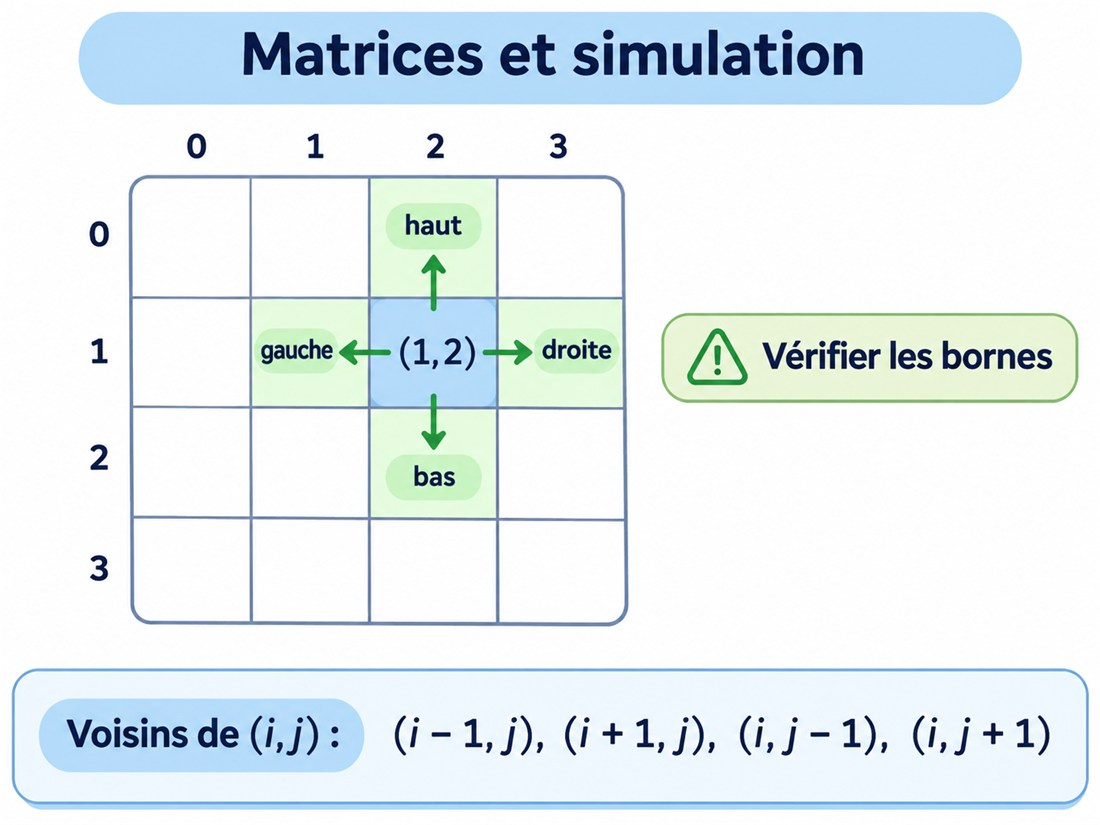

Sur l'image, la case courante est `(1, 2)` : ligne 1, colonne 2. Ses voisins sont `(0, 2)` en haut, `(2, 2)` en bas, `(1, 1)` à gauche et `(1, 3)` à droite. En général, depuis `(i, j)` :

| Direction | Ligne | Colonne | Décalage `(di, dj)` |
|---|---|---|---|
| haut | i − 1 | j | (−1, 0) |
| bas | i + 1 | j | (+1, 0) |
| gauche | i | j − 1 | (0, −1) |
| droite | i | j + 1 | (0, +1) |

Plutôt que d'écrire quatre fois presque le même code, on range les quatre décalages dans une liste et on boucle dessus. C'est une astuce qui reviendra dans **tous** les problèmes de grille.

In [ ]:
DIRECTIONS = [(-1, 0), (1, 0), (0, -1), (0, 1)]   # haut, bas, gauche, droite

i, j = 1, 1
for di, dj in DIRECTIONS:
    ni, nj = i + di, j + dj           # (ni, nj) = coordonnées du voisin
    print(f"décalage ({di:+d},{dj:+d}) → voisin ({ni},{nj}) = {m[ni][nj]}")

# Pour ajouter les diagonales, il suffit d'ajouter (-1,-1), (-1,1), (1,-1), (1,1).

### Le piège des bords, et pourquoi il est sournois
Pour la case `(0, 0)` (coin en haut à gauche), le voisin du haut serait `(-1, 0)`. Il n'existe pas… mais **Python ne plante pas** :

In [ ]:
print(m[-1][0])   # 7 ?! En Python, l'indice -1 veut dire « le dernier élément »

Python renvoie une case de la **dernière ligne** : pas d'erreur, juste un **résultat faux**, en silence. (Vers le bas ou la droite, `m[3][0]` plante avec `IndexError` : c'est presque mieux, au moins on le voit.)

D'où la règle : **avant de lire un voisin, on vérifie qu'il est dans la grille.**
```python
if 0 <= ni < lignes and 0 <= nj < colonnes:
```
À lire : « `ni` est entre 0 (inclus) et `lignes` (exclu), et pareil pour `nj` ».

### La solution du problème de départ

In [ ]:
def somme_voisins_orthogonaux(matrice, i, j):
    if not matrice or not matrice[0]:      # grille vide : rien à additionner
        return 0

    lignes = len(matrice)
    colonnes = len(matrice[0])
    total = 0

    for di, dj in [(-1, 0), (1, 0), (0, -1), (0, 1)]:    # haut, bas, gauche, droite
        ni, nj = i + di, j + dj
        if 0 <= ni < lignes and 0 <= nj < colonnes:      # ce voisin existe-t-il ?
            total += matrice[ni][nj]

    return total

m = [
    [1, 2, 3],
    [4, 5, 6],
    [7, 8, 9],
]
print(somme_voisins_orthogonaux(m, 1, 1))   # centre : 2 + 8 + 4 + 6 = 20
print(somme_voisins_orthogonaux(m, 0, 0))   # coin   : bas (4) + droite (2) = 6

**Trace à la main pour le coin `(0, 0)` :**

| Direction | `(ni, nj)` | Dans la grille ? | `total` |
|---|---|---|---|
| haut | (−1, 0) | non (`ni < 0`) | 0 |
| bas | (1, 0) | oui → +4 | 4 |
| gauche | (0, −1) | non (`nj < 0`) | 4 |
| droite | (0, 1) | oui → +2 | 6 |

## La simulation : faire évoluer une grille étape par étape
« Simulation » veut dire : l'énoncé donne des **règles**, et on doit les **appliquer**, souvent pendant plusieurs tours. Exemple :

> Une grille contient des 0 (case saine) et des 1 (case malade). À chaque tour, toute case saine qui touche (haut/bas/gauche/droite) une case malade devient malade. Donne la grille après **un** tour.

Le piège classique : **modifier la grille pendant qu'on la lit**. Une case qui vient juste de tomber malade va contaminer sa voisine **dans le même tour**, ce qui est faux. Regarde :

In [ ]:
def un_tour_FAUX(grille):
    lignes, colonnes = len(grille), len(grille[0])
    for i in range(lignes):
        for j in range(colonnes):
            if grille[i][j] == 0:
                for di, dj in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
                    ni, nj = i + di, j + dj
                    if 0 <= ni < lignes and 0 <= nj < colonnes and grille[ni][nj] == 1:
                        grille[i][j] = 1      # ❌ on écrit dans la grille qu'on est en train de lire
                        break
    return grille

print(un_tour_FAUX([[1, 0, 0, 0]]))   # attendu [[1, 1, 0, 0]] … on obtient [[1, 1, 1, 1]]

La case 1 devient malade ; puis la case 2 voit la case 1 (déjà modifiée) et devient malade à son tour ; etc. Tout est contaminé en un seul tour.

**La correction** : on **lit** l'ancienne grille et on **écrit** dans une copie.

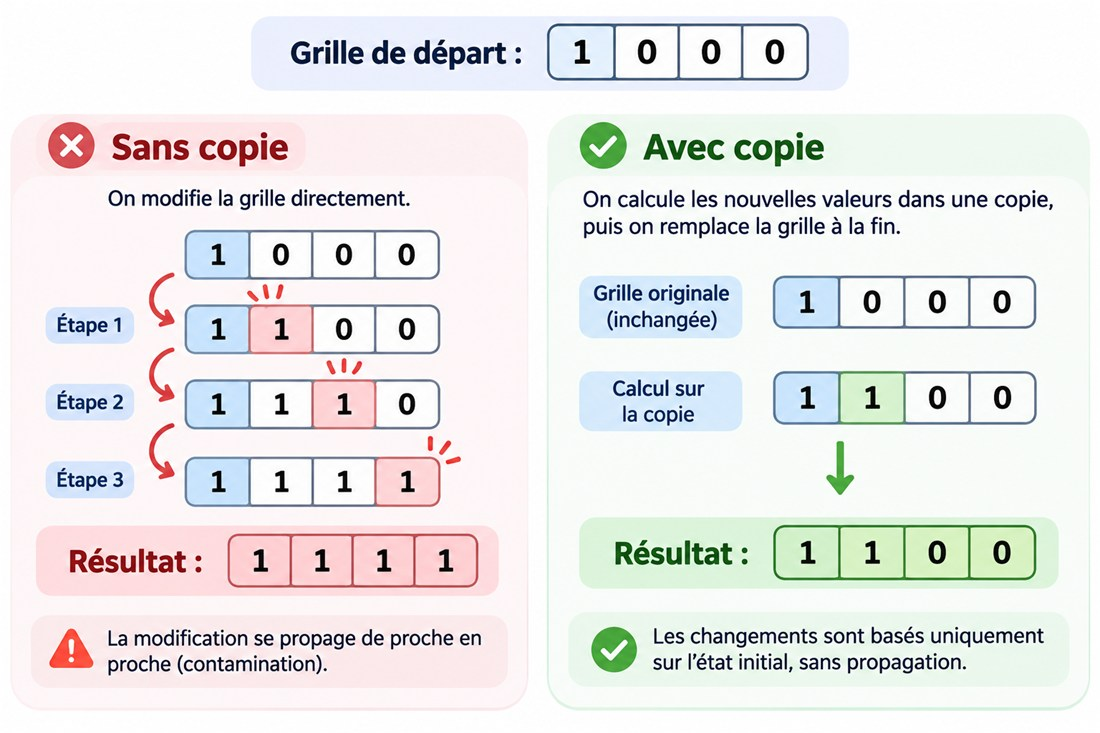

Sur l'image, à gauche, les « étapes » se passent toutes **pendant un seul tour**, au fil de la double boucle : chaque case contaminée contamine aussitôt la suivante → `[1, 1, 1, 1]`. À droite, on lit la grille d'origine, qui ne change pas, et on écrit dans une copie : seule la voisine directe de la case malade est contaminée → `[1, 1, 0, 0]`.

In [ ]:
def un_tour(grille):
    lignes, colonnes = len(grille), len(grille[0])
    nouvelle = [ligne[:] for ligne in grille]     # copie : on LIT grille, on ÉCRIT nouvelle
    for i in range(lignes):
        for j in range(colonnes):
            if grille[i][j] == 0:
                for di, dj in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
                    ni, nj = i + di, j + dj
                    if 0 <= ni < lignes and 0 <= nj < colonnes and grille[ni][nj] == 1:
                        nouvelle[i][j] = 1
                        break
    return nouvelle

g = [[1, 0, 0, 0]]
print(un_tour(g))             # un tour   : [[1, 1, 0, 0]]
print(un_tour(un_tour(g)))    # deux tours : [[1, 1, 1, 0]]

### Copier une grille correctement
Pourquoi `[ligne[:] for ligne in grille]` et pas plus simple ? Parce qu'une variable Python n'est qu'une **étiquette** posée sur un objet : `b = a` ne copie rien, ça colle une deuxième étiquette sur la même liste.

In [ ]:
grille = [[0, 0], [0, 0]]

alias = grille                             # ❌ même grille, deux noms
copie_surface = grille.copy()              # ❌ nouvelle liste extérieure… mais les MÊMES lignes dedans
copie_ok = [ligne[:] for ligne in grille]  # ✅ chaque ligne est copiée

grille[0][0] = 9
print(alias[0][0], copie_surface[0][0], copie_ok[0][0])   # 9 9 0

# Même problème pour CRÉER une grille :
piege = [[0] * 3] * 3            # ❌ 3 fois la MÊME ligne
piege[0][0] = 1
print(piege)                     # [[1, 0, 0], [1, 0, 0], [1, 0, 0]] !

ok = [[0] * 3 for _ in range(3)] # ✅ 3 lignes différentes
ok[0][0] = 1
print(ok)

## Quand y penser ?
- grille, plateau, carte, image, labyrinthe, tableau 2D ;
- « voisins », « adjacent », « haut / bas / gauche / droite », « 8 directions » ;
- « à chaque tour / étape / génération » → **simulation, avec une copie**.

## Les pièges
- Confondre `i` (ligne) et `j` (colonne), ou `len(m)` et `len(m[0])`.
- Oublier de vérifier les bornes — surtout avec `-1`, qui ne plante pas.
- Modifier la grille pendant qu'on la lit dans une simulation.
- `[[0] * c] * l` : les lignes sont partagées.
- Ne tester que des grilles carrées : teste aussi une grille 2×3 ou 1×n !

## À toi de jouer — compter les pics
> Une case est un **pic** si sa valeur est **strictement plus grande** que celle de **tous** ses voisins existants (haut, bas, gauche, droite). Une case sans aucun voisin compte comme un pic. Écris `compter_pics(grille)`.
> ```
> [[1, 4, 1],
>  [2, 1, 3],
>  [5, 1, 1]]
> ```
> → `3` : le 4 (voisins 1, 1, 1), le 3 (voisins 1, 1, 1) et le 5 (voisins 2, 1).

**Indice** : réutilise le schéma « boucle sur les 4 directions + vérification des bornes ». Pour chaque case, pars de `est_pic = True` et passe à `False` dès qu'un voisin est `>=`.

In [ ]:
def compter_pics(grille):
    # À toi de jouer !
    pass

verifier(compter_pics, [
    (([[1, 4, 1], [2, 1, 3], [5, 1, 1]],), 3),
    (([[7]],), 1),                 # aucun voisin → pic
    (([[1, 1], [1, 1]],), 0),      # « strictement » plus grand
    (([[1, 2, 3]],), 1),           # une seule ligne
    (([[3], [2], [1]],), 1),       # une seule colonne
])

<details>
<summary><b>Voir la solution</b> (essaie vraiment d'abord !)</summary>

```python
def compter_pics(grille):
    if not grille or not grille[0]:
        return 0
    lignes, colonnes = len(grille), len(grille[0])
    pics = 0
    for i in range(lignes):
        for j in range(colonnes):
            est_pic = True
            for di, dj in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
                ni, nj = i + di, j + dj
                if 0 <= ni < lignes and 0 <= nj < colonnes and grille[ni][nj] >= grille[i][j]:
                    est_pic = False     # un voisin aussi haut ou plus haut : pas un pic
                    break
            if est_pic:
                pics += 1
    return pics
```

</details>

---

**Suite :** [Thème 3 — Fenêtre glissante (sliding window) et deux pointeurs (two pointers)](theme3_fenetre_deux_pointeurs.ipynb) ➡ · [Retour au sommaire](00_sommaire.ipynb)

**S'entraîner :** [Série 2 — Matrices et simulation](exercices/serie2_matrices_simulation.ipynb) (6 exercices avec tests automatiques)